# Model 05: Expense Prediction
### College Data Mining & DWDM Laboratory Submission
**Algorithm:** Multiple Linear Regression  
**Problem Type:** Regression for Operational Overheads  
**Key Concepts Demonstrated:**
- Syllabus-aligned algorithm implementation
- Data preprocessing & descriptive statistics
- Model training, hyperparameter tuning & evaluation
- Joblib model serialization and sample inference


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Ensure parent directory is in path
sys.path.append(os.path.abspath(".."))
from preprocessing.preprocess import load_dataset, clean_and_impute

# Load and clean dataset
df = load_dataset()
df_clean = clean_and_impute(df)
print(f"Dataset ready: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")
df_clean.head(3)


Dataset ready: 1000 rows, 30 columns


,date,day_of_week,is_weekend,product_name,category,price,discount,previous_day_sales,sales_7_day_average,sales_30_day_average,...,sales_90_day,turnover_rate,days_since_last_sale,category_label,inventory_status,business_activity,total_expense,expense_3_month_average,average_order_value,profit
0,2024-01-01,Monday,0,Laundry Detergent 1kg,Household,210.0,10.43,3599.34,3599.34,3599.34,...,205357.08,3.62,12,MEDIUM_DEMAND,RESTOCK,14.87,3044.67,3044.67,97.28,-275.43
1,2024-01-02,Tuesday,0,Basmati Rice 5kg,Grocery,450.0,2.96,3599.34,3656.81,3656.81,...,316258.19,3.77,1,MEDIUM_DEMAND,RESTOCK,15.39,3100.65,3072.66,95.24,-358.75
2,2024-01-03,Wednesday,0,Organic Honey 500g,Grocery,280.0,6.88,3714.28,3750.13,3750.13,...,159407.77,5.20,0,MEDIUM_DEMAND,RESTOCK,12.33,3445.75,3197.02,115.79,-448.90


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

feature_cols = ["previous_day_sales", "sales_7_day_average", "invoice_count", "business_activity", "expense_3_month_average"]
target_col = "total_expense"
split_idx = int(len(df_clean) * 0.8)

X_train, y_train = df_clean.iloc[:split_idx][feature_cols].values, df_clean.iloc[:split_idx][target_col].values
X_test, y_test = df_clean.iloc[split_idx:][feature_cols].values, df_clean.iloc[split_idx:][target_col].values

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Expense Model Evaluation:")
print(f"  MAE:  Rs. {mean_absolute_error(y_test, y_pred):.2f}")
print(f"  RMSE: Rs. {root_mean_squared_error(y_test, y_pred):.2f}")
print(f"  R²:   {r2_score(y_test, y_pred):.4f}")


Expense Model Evaluation:
  MAE:  Rs. 158.11
  RMSE: Rs. 207.27
  R²:   0.6180


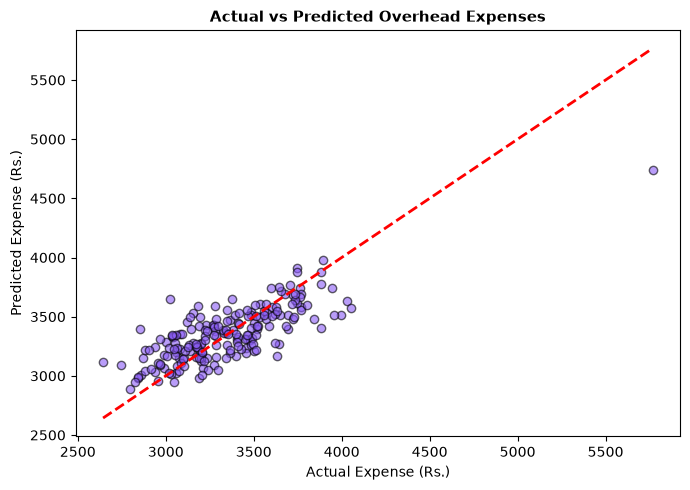

In [3]:
# Scatter Plot: Actual vs Predicted
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='#8b5cf6', alpha=0.6, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title("Actual vs Predicted Overhead Expenses", fontsize=11, fontweight='bold')
plt.xlabel("Actual Expense (Rs.)")
plt.ylabel("Predicted Expense (Rs.)")
plt.tight_layout()
plt.show()


In [4]:
# Joblib Save & Test
joblib.dump(model, "../models/expense_model.joblib")
del model
loaded_model = joblib.load("../models/expense_model.joblib")

sample = np.array([[5200.0, 4900.0, 42, 68.5, 3100.0]])
print(f"Predicted Total Expense for Sample: Rs. {loaded_model.predict(sample)[0]:.2f}")


Predicted Total Expense for Sample: Rs. 4188.56
